# BLOQUE 4: Validación Unificada, Selección del Modelo Ganador (*Champion Model*), Diagnóstico de Residuos y Explicabilidad (XAI)
## Benchmarking Imparcial de 18 Modelos Fuera de Muestra (LOOCV, $N=24$), Inferencia No Paramétrica y Explicabilidad Geometalúrgica

**Trabajo de Titulación para optar al título de Ingeniero Civil en Minas**  
**Universidad de Antofagasta** — Facultad de Ingeniería, Departamento de Ingeniería en Minas  

* **Autor:** Felipe Andrés Guerra Maturana  
* **Profesor Guía:** Dr. José Delgado Vega (*Doctor en Geología, Especialista en Geoestadística y Explotaciones Mineras, École des Mines de Paris*)  
* **Caso de Estudio:** Faena Mantos Cobrizo (Distrito Minero Los Cóndores) / ENAMI (Planta San José)  
* **Módulo:** Bloque 4 — Validación Predictiva, Diagnóstico de Residuos, Selección de Modelo y Explicabilidad (XAI)  
* **Ubicación:** `./BLOQUE_4/`  
* **Versión Metodológica:** 4.0 (Línea Temporal Estricta — Cero Fuga, Rigor Econométrico e Inferencia Robusta)  

---

### Objetivos del Bloque 4:
1. **Consolidar la matriz maestra unificada de 18 modelos evaluados bajo el estándar LOOCV ($N = 24$)**:
   * Contrastar de forma imparcial los $7$ baselines del Bloque 2 (`Cancha Directa`, `Baseline 1B`, `OLS`, `RidgeCV`, `LassoCV`, `ElasticNetCV`, `SVR`) y las $11$ redes neuronales del Bloque 3 (`RNA_Delgado_Keras`, `RNA_Delgado_MLP`, grilla directa `(2,)` a `(3, 2)` y familia `Residual-MLP`).
2. **Computar la batería exhaustiva de 9 métricas de validación**:
   * Reportar formalmente el **Error Cuadrático Medio (MSE, en $(\%\text{Cu})^2$)**, junto a $\text{RMSE}$, $\text{MAE}$, $\text{NRMSE}\%$, $R^2$, $\text{MAPE}\%$, correlación de Pearson $r$, Sesgo Medio y Varianza Explicada.
3. **Auditar la validez estadística de los residuos condicionales**:
   * Evaluar Normalidad (Shapiro-Wilk), Homocedasticidad (Breusch-Pagan) e Independencia Serial (Durbin-Watson $d \approx 2$).
   * Ejecutar la prueba pareada no paramétrica de **Wilcoxon unilateral** frente a Cancha Directa y bilateral frente a Baseline 1B, junto con intervalos de confianza Bootstrap ($B = 10{,}000$).
4. **Formular la Selección Dual del Modelo Ganador (*Champion Model*)**:
   * Declarar el benchmark de **máxima robustez y mínima varianza ante extremos**: `Baseline 1B` / `Residual-MLP` ($\text{NRMSE} = 10.07\%$, $R^2 = +0.6504$).
   * Declarar el modelo de **mayor explicabilidad geometalúrgica no lineal**: `RNA_MLP_2` ($\text{NRMSE} = 12.28\%$ en LOOCV, $6.56\%$ en Holdout, $R^2 = +0.4803$).
5. **Interpretabilidad Profunda y Explicabilidad Geometalúrgica (XAI)**:
   * Generar la **Superficie de Respuesta 2D** demostrando el efecto penalizador de $\text{CuS}$ sobre la flotación comercial en ENAMI.
   * Cuantificar el aporte de $\text{CuT}$ y $\text{CuS}$ mediante **SHAP (`KernelExplainer`)** e **Importancia por Permutación**, documentando la contracción de pesos en `Residual-MLP`.
6. **Serializar los pipelines finales entrenados en $N = 24$ (`.joblib`)**:
   * Generar los artefactos binarios que alimentarán el **Bloque 5 (Modelo Económico ENAMI)** y el **Bloque 6 (Aplicación Web Streamlit)**.

In [1]:
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
import joblib

warnings.filterwarnings('ignore')

# Configuración de gráficos de publicación (200 DPI)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.autolayout'] = True

print("Entorno verificado para el Bloque 4:")
print(f"NumPy: {np.__version__} | Pandas: {pd.__version__} | Scipy: {scipy.__version__} | Joblib: {joblib.__version__}")


Entorno verificado para el Bloque 4:
NumPy: 2.4.0 | Pandas: 2.3.3 | Scipy: 1.17.1 | Joblib: 1.5.3


## 1. Carga y Consolidación de Predicciones Fuera de Muestra (LOOCV, $N = 24$)

Conforme a la **Metodología v4.0**, todos los modelos fueron evaluados bajo la misma partición ciega cronológica de validación cruzada dejando uno fuera (**LOOCV**, $N = 24$). A continuación se cargan y fusionan las predicciones del **Bloque 2** (7 baselines) y del **Bloque 3** (11 redes neuronales):

In [2]:
# Carga de la matriz consolidada de predicciones OOS
df_oos = pd.read_csv("PREDICCIONES_OOS_TODOS_LOS_MODELOS.csv")
fechas = df_oos['Fecha'].values
y_true = df_oos['Canje_CuT'].values
N = len(y_true)

print(f"Matriz consolidada cargada: N = {N} periodos mensuales (2023-01 a 2024-12).")
print(f"Modelos presentes: {len(df_oos.columns) - 2} modelos de predicción.")
df_oos.head(10)


Matriz consolidada cargada: N = 24 periodos mensuales (2023-01 a 2024-12).
Modelos presentes: 18 modelos de predicción.


,Fecha,Canje_CuT,Pred_Cancha_Directa,Pred_Baseline_1B,Pred_OLS,Pred_RidgeCV,Pred_LassoCV,Pred_ElasticNetCV,Pred_SVR_RBF,Pred_RNA_Delgado_Keras,Pred_RNA_Delgado_MLP,Pred_RNA_MLP_2,Pred_RNA_MLP_3,Pred_RNA_MLP_4,Pred_RNA_MLP_2_2,Pred_RNA_MLP_3_2,Pred_Res_MLP_2,Pred_Res_MLP_2_2,Pred_Res_MLP_3,Pred_Res_MLP_4
0,2023-01,1.55,2.16,1.8313,1.7934,1.7469,1.7832,1.7748,1.8343,1.7934,1.7500,1.8128,1.6953,1.6954,1.6520,1.7600,1.8313,1.8313,1.8313,1.8313
1,2023-02,1.41,1.76,1.4200,1.4139,1.4122,1.4148,1.4139,1.4539,1.4140,1.4081,1.4187,1.4127,1.4126,1.4176,1.3981,1.4200,1.4200,1.4200,1.4200
2,2023-03,1.49,1.73,1.3852,1.4101,1.4280,1.4096,1.4127,1.7112,1.4090,1.4197,1.5501,1.4297,1.4307,1.4229,1.4190,1.3852,1.3852,1.3852,1.3852
3,2023-04,1.38,1.66,1.3170,1.3356,1.3537,1.3378,1.3404,1.3499,1.3353,1.3425,1.3224,1.3610,1.3618,1.3788,1.3566,1.3170,1.3170,1.3170,1.3170
4,2023-05,1.24,1.80,1.4691,1.4472,1.4263,1.4480,1.4452,1.4590,1.4499,1.4293,1.4482,1.4250,1.4251,1.4332,1.4092,1.4691,1.4691,1.4691,1.4691
5,2023-06,1.34,1.77,1.4335,1.4140,1.4036,1.4161,1.4126,1.3437,1.4140,1.4004,1.4155,1.4026,1.4026,1.4147,1.3859,1.4335,1.4335,1.4335,1.4335
6,2023-07,1.37,1.75,1.4113,1.3956,1.3897,1.3979,1.3952,1.3444,1.3956,1.3850,1.3907,1.3900,1.3899,1.4055,1.3749,1.4113,1.4113,1.4113,1.4113
7,2023-08,1.52,1.74,1.3943,1.3595,1.3526,1.3623,1.3593,1.2896,1.3600,1.3336,1.3306,1.3507,1.3499,1.3754,1.3366,1.3943,1.3944,1.3943,1.3943
8,2023-09,1.55,2.01,1.6748,1.5898,1.5040,1.5895,1.5723,1.0603,1.5913,1.4999,1.3739,1.4942,1.4927,1.4941,1.4411,1.6748,1.6748,1.6748,1.6748
9,2023-10,1.79,2.21,1.8730,2.1184,2.0014,2.1179,2.1184,2.0103,2.0738,2.0801,1.8532,2.0568,2.0418,1.8559,1.8985,1.8730,1.8730,1.8730,1.8730


## 2. Benchmarking Unificado de Desempeño Fuera de Muestra

Se computan las 9 métricas exhaustivas sobre las 24 predicciones ciegas, incluyendo el **Error Cuadrático Medio (MSE, en $(\%\text{Cu})^2$)**:
$$\text{MSE} = \frac{1}{N}\sum_{k=1}^N (y_k - \hat{y}_k)^2, \qquad \text{RMSE} = \sqrt{\text{MSE}}, \qquad \text{NRMSE} = \frac{\text{RMSE}}{\bar{y}} \times 100\%$$

In [3]:
# Carga y despliegue de la tabla maestra de benchmarking
df_metrics = pd.read_csv("TABLA_UNIFICADA_BENCHMARKING_18_MODELOS.csv")
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print("=== TABLA 2.1: BENCHMARKING UNIFICADO DE DESEMPEÑO PREDICTIVO (18 MODELOS, N=24) ===")
df_metrics[['Ranking', 'Modelo', 'Familia', 'Espacio_Entradas', 'MSE (%Cu)^2', 'RMSE (%Cu)', 'NRMSE (%)', 'R2 Score', 'MAPE (%)', 'Sesgo (%Cu)']]


=== TABLA 2.1: BENCHMARKING UNIFICADO DE DESEMPEÑO PREDICTIVO (18 MODELOS, N=24) ===


,Ranking,Modelo,Familia,Espacio_Entradas,MSE (%Cu)^2,RMSE (%Cu),NRMSE (%),R2 Score,MAPE (%),Sesgo (%Cu)
0,1,Res_MLP_2_2,"Residual-MLP (2, 2)","2D [CuT, CuS]",0.020781,0.144157,10.072130,0.650357,8.122392,9.251859e-18
1,2,Baseline_1B,Baseline Corrección Sesgo,1D [Cancha],0.020782,0.144161,10.072384,0.650340,8.122666,-4.166667e-06
2,3,Res_MLP_4,"Residual-MLP (4,)","2D [CuT, CuS]",0.020782,0.144161,10.072384,0.650340,8.122666,-4.166667e-06
3,4,Res_MLP_3,"Residual-MLP (3,)","2D [CuT, CuS]",0.020782,0.144161,10.072384,0.650340,8.122666,-4.166667e-06
4,5,Res_MLP_2,"Residual-MLP (2,)","2D [CuT, CuS]",0.021551,0.146802,10.256891,0.637412,8.221075,-2.212500e-03
5,6,RNA_Delgado_Keras,Directa (Keras Colapsada),"2D [CuT, CuS]",0.027735,0.166537,11.635783,0.533369,8.740503,2.162500e-03
6,7,RidgeCV,Lineal Regularizado (L2),"2D [CuT, CuS]",0.028403,0.168532,11.775133,0.522126,8.931311,1.083750e-02
7,8,OLS,Regresión Lineal Clásica,"2D [CuT, CuS]",0.028789,0.169673,11.854891,0.515630,8.819816,3.837500e-03
8,9,RNA_MLP_2,"Directa MLP (2,)","2D [CuT, CuS]",0.030890,0.175754,12.279776,0.480288,8.953073,-1.236250e-02
9,10,LassoCV,Lineal Regularizado (L1),"2D [CuT, CuS]",0.030971,0.175985,12.295921,0.478920,9.226357,8.654167e-03


## 3. Diagnóstico Estadístico Riguroso de Residuos e Inferencia

Para evaluar la validez econométrica de las predicciones, se auditan los residuos fuera de muestra ($e_k = y_k - \hat{y}_k$) mediante:
1. **Normalidad (Shapiro-Wilk):** Contrasta si la distribución de los errores es gaussiana ($p \ge 0.05$).
2. **Independencia Serial (Durbin-Watson):** Determina la presencia de autocorrelación de primer orden ($d \approx 2.0$ indica ausencia de correlación).
3. **Homocedasticidad (Breusch-Pagan):** Evalúa si la varianza del error depende del valor predicho ($p \ge 0.05$).
4. **Prueba Pareada No Paramétrica de Wilcoxon (Unilateral):** Evalúa si el error cuadrático del modelo es significativamente inferior al de la Cancha Directa ($p < 0.05$).
5. **Intervalo de Confianza Bootstrap al 95% ($B = 10{,}000$):** Estima el intervalo de dispersión muestral del $\text{RMSE}$.

In [4]:
# Carga y despliegue del diagnóstico estadístico de residuos
df_diag = pd.read_csv("DIAGNOSTICO_RESIDUOS_Y_PRUEBAS_HIPOTESIS.csv")

print("=== TABLA 3.1: DIAGNÓSTICO ESTADÍSTICO DE RESIDUOS E INFERENCIA NO PARAMÉTRICA ===")
df_diag[['Modelo', 'RMSE (%Cu)', 'Bootstrap_RMSE_CI_2.5%', 'Bootstrap_RMSE_CI_97.5%', 'Shapiro_W', 'Shapiro_p_value', 'Durbin_Watson_d', 'Homocedasticidad', 'Wilcoxon_vs_Cancha_p_unilateral']]


=== TABLA 3.1: DIAGNÓSTICO ESTADÍSTICO DE RESIDUOS E INFERENCIA NO PARAMÉTRICA ===


,Modelo,RMSE (%Cu),Bootstrap_RMSE_CI_2.5%,Bootstrap_RMSE_CI_97.5%,Shapiro_W,Shapiro_p_value,Durbin_Watson_d,Homocedasticidad,Wilcoxon_vs_Cancha_p_unilateral
0,Cancha_Directa,0.367384,0.315257,0.416876,0.985214,0.969549,0.284876,Homocedástico,1.000000
1,Baseline_1B,0.144161,0.106120,0.178486,0.985216,0.969568,2.014457,Homocedástico,0.000064
2,OLS,0.169673,0.118808,0.215903,0.979265,0.881942,2.309508,Heterocedástico,0.000088
3,RidgeCV,0.168532,0.115043,0.225491,0.907790,0.031592,2.091864,Heterocedástico,0.000103
4,LassoCV,0.175985,0.120549,0.230999,0.967104,0.596265,2.364483,Heterocedástico,0.000161
5,ElasticNetCV,0.176900,0.121299,0.233171,0.961575,0.470885,2.382781,Heterocedástico,0.000161
6,SVR_RBF,0.238717,0.157914,0.314668,0.929628,0.095637,2.148048,Homocedástico,0.001407
7,RNA_Delgado_Keras,0.166537,0.118212,0.213057,0.970509,0.679578,2.271449,Heterocedástico,0.000075
8,RNA_Delgado_MLP,0.180532,0.122097,0.241893,0.947343,0.237145,2.256844,Heterocedástico,0.000186
9,RNA_MLP_2,0.175754,0.115402,0.238431,0.930730,0.101221,1.958363,Homocedástico,0.000186


## 4. Selección Dual del Modelo Ganador (*Champion Model*)

El análisis econométrico y geoestadístico revela dos arquetipos complementarios de alta relevancia para la faena Mantos Cobrizo:

### 4.1. Campeón de Mínima Varianza y Robustez Ante Extremos: `Baseline 1B` / `Residual-MLP`
* **Desempeño Global:** $\text{NRMSE} = 10.07\%$, $\text{RMSE} = 0.1442\%\text{Cu}$, $R^2 = +0.6504$, $\text{MSE} = 0.020781\,(\%\text{Cu})^2$.
* **Mecanismo Subyacente:** La regularización $L_2$ con $\alpha = 2.0$ en la red residual contrae la norma de pesos a cero ($\Vert\mathbf{W}\Vert \to 0$), haciendo que $\hat{e}_{\text{MLP}} \to \bar{e}_{\text{train}}$ y reproduciendo en los 24 meses la corrección de sesgo constante ($+0.3404\%\text{Cu}$).
* **Idoneidad Operacional:** Es el estimador insuperable para mitigar el riesgo presupuestario global cuando no se dispone de control selectivo sobre las proporciones de mineral oxidado.

### 4.2. Campeón de Explicabilidad Geometalúrgica No Lineal: `RNA_MLP_2`
* **Desempeño LOOCV:** $\text{NRMSE} = 12.28\%$, $\text{RMSE} = 0.1758\%\text{Cu}$, $R^2 = +0.4803$, $\text{MSE} = 0.030890\,(\%\text{Cu})^2$.
* **Desempeño Prospectivo (*Holdout* 19/5):** $\text{NRMSE} = 6.56\%$ (frente a $8.96\%$ de Baseline 1B y $7.57\%$ de RidgeCV).
* **Parsimonia:** Exactamente $9$ parámetros nominales ($2$ neuronas ocultas, activación `tanh`, $\text{Ratio } N_{\text{train}}/P = 23/9 = 2.56$).
* **Idoneidad Operacional:** Es el único modelo con pesos activos no nulos que captura cuantitativamente el impacto de la solubilidad del cobre (`Cancha_CuS`), permitiendo la optimización selectiva de frentes de carguío y blending.

In [5]:
# Carga del resumen consolidado de los modelos campeones
df_champ = pd.read_csv("metricas_validadas_champion.csv")
print("=== TABLA 4.1: MATRIZ DE COMPARACIÓN DE ESTRATEGIAS CAMPEONAS ===")
df_champ


=== TABLA 4.1: MATRIZ DE COMPARACIÓN DE ESTRATEGIAS CAMPEONAS ===


,Ranking,Modelo,Familia,Espacio_Entradas,MSE (%Cu)^2,RMSE (%Cu),MAE (%Cu),NRMSE (%),R2 Score,MAPE (%),Pearson r,Sesgo (%Cu),Var Explicada
0,1,Res_MLP_2_2,"Residual-MLP (2, 2)","2D [CuT, CuS]",0.020781,0.144157,0.117750,10.072130,0.650357,8.122392,0.820891,9.251859e-18,0.650357
1,2,Baseline_1B,Baseline Corrección Sesgo,1D [Cancha],0.020782,0.144161,0.117754,10.072384,0.650340,8.122666,0.820882,-4.166667e-06,0.650340
2,7,RidgeCV,Lineal Regularizado (L2),"2D [CuT, CuS]",0.028403,0.168532,0.130062,11.775133,0.522126,8.931311,0.724756,1.083750e-02,0.524102
3,8,OLS,Regresión Lineal Clásica,"2D [CuT, CuS]",0.028789,0.169673,0.131754,11.854891,0.515630,8.819816,0.734635,3.837500e-03,0.515878
4,9,RNA_MLP_2,"Directa MLP (2,)","2D [CuT, CuS]",0.030890,0.175754,0.131846,12.279776,0.480288,8.953073,0.695370,-1.236250e-02,0.482859
5,18,Cancha_Directa,Línea Base Operacional,1D [Cancha],0.134971,0.367384,0.340417,25.668735,-1.270862,24.895926,0.834665,3.404167e-01,0.678859


## 5. Explicabilidad Geometalúrgica (XAI): SHAP y Permutación

Para responder a la necesidad de interpretabilidad en la toma de decisiones operacionales, se analiza la contribución marginal de los predictores sobre `RNA_MLP_2` y se contrasta formalmente con `Res_MLP_2_2`:

In [6]:
# Despliegue de los resultados de explicabilidad XAI
df_xai = pd.read_csv("XAI_IMPORTANCIA_VARIABLES.csv")
df_shap_mes = pd.read_csv("SHAP_VALORES_POR_MES_RNA_MLP_2.csv")

print("=== TABLA 5.1: IMPORTANCIA DE VARIABLES (PERMUTACIÓN Y SHAP) ===")
display(df_xai)

print("\n=== TABLA 5.2: PRIMEROS 6 MESES DE VALORES SHAP CONDICIONALES (RNA_MLP_2) ===")
display(df_shap_mes.head(6))


=== TABLA 5.1: IMPORTANCIA DE VARIABLES (PERMUTACIÓN Y SHAP) ===


,Modelo,Variable,Permutation_Importance_Mean,Permutation_Importance_Std,Mean_Abs_SHAP
0,RNA_MLP_2,Cancha_CuT,1.256049e-01,2.975743e-02,0.092228
1,RNA_MLP_2,Cancha_CuS,1.002733e-01,2.163507e-02,0.070106
2,Res_MLP_2_2,Cancha_CuT,1.973820e-01,3.865828e-02,0.197667
3,Res_MLP_2_2,Cancha_CuS,-8.920642e-17,1.381786e-15,0.000000



=== TABLA 5.2: PRIMEROS 6 MESES DE VALORES SHAP CONDICIONALES (RNA_MLP_2) ===


,Fecha,Cancha_CuT,Cancha_CuS,Canje_Real,SHAP_Cancha_CuT,SHAP_Cancha_CuS,Base_Value
0,2023-01,2.16,0.17,1.55,0.035139,0.124058,1.448847
1,2023-02,1.76,0.14,1.41,0.008817,-0.043453,1.448847
2,2023-03,1.73,0.16,1.49,0.004273,0.071745,1.448847
3,2023-04,1.66,0.14,1.38,-0.069067,-0.050788,1.448847
4,2023-05,1.80,0.13,1.24,0.024733,-0.056384,1.448847
5,2023-06,1.77,0.13,1.34,0.008866,-0.058062,1.448847


## 6. Verificación de Pipelines y Modelos Serializados (`.joblib`)

Los modelos reentrenados sobre el total de la historia disponible ($N = 24$) quedan encapsulados y listos para inferencia determinista en el **Bloque 5** y **Bloque 6**:

In [7]:
# Definición de clases para deserialización limpia con joblib
SEEDS = [42, 101, 2023, 7, 13, 99, 123, 456, 789, 999]

class MultiSeedEnsembleMLP(BaseEstimator, RegressorMixin):
    def __init__(self, hidden_layer_sizes=(2,), activation='tanh', solver='lbfgs',
                 alpha=0.001, seeds=SEEDS, max_iter=3000, tol=1e-5):
        self.hidden_layer_sizes = hidden_layer_sizes
        self.activation = activation
        self.solver = solver
        self.alpha = alpha
        self.seeds = seeds
        self.max_iter = max_iter
        self.tol = tol
        self.models_ = []
        self.scaler_ = StandardScaler()
        
    def fit(self, X, y):
        X_scaled = self.scaler_.fit_transform(X)
        self.models_ = []
        for s in self.seeds:
            m = MLPRegressor(hidden_layer_sizes=self.hidden_layer_sizes,
                             activation=self.activation,
                             solver=self.solver,
                             alpha=self.alpha,
                             max_iter=self.max_iter,
                             tol=self.tol,
                             random_state=s)
            m.fit(X_scaled, y)
            self.models_.append(m)
        return self
        
    def predict(self, X):
        X_scaled = self.scaler_.transform(X)
        preds = np.column_stack([m.predict(X_scaled) for m in self.models_])
        return np.mean(preds, axis=1)

class ResidualEnsembleMLP(BaseEstimator, RegressorMixin):
    def __init__(self, hidden_layer_sizes=(2, 2), activation='relu', solver='lbfgs',
                 alpha=2.0, seeds=SEEDS, max_iter=3000, tol=1e-5):
        self.hidden_layer_sizes = hidden_layer_sizes
        self.activation = activation
        self.solver = solver
        self.alpha = alpha
        self.seeds = seeds
        self.max_iter = max_iter
        self.tol = tol
        self.models_ = []
        self.scaler_ = StandardScaler()
        
    def fit(self, X, y):
        e_target = X[:, 0] - y
        X_scaled = self.scaler_.fit_transform(X)
        self.models_ = []
        for s in self.seeds:
            m = MLPRegressor(hidden_layer_sizes=self.hidden_layer_sizes,
                             activation=self.activation,
                             solver=self.solver,
                             alpha=self.alpha,
                             max_iter=self.max_iter,
                             tol=self.tol,
                             random_state=s)
            m.fit(X_scaled, e_target)
            self.models_.append(m)
        return self
        
    def predict(self, X):
        X_scaled = self.scaler_.transform(X)
        bias_preds = np.column_stack([m.predict(X_scaled) for m in self.models_])
        mean_bias = np.mean(bias_preds, axis=1)
        return X[:, 0] - mean_bias

# Verificación de carga y predicción con pipelines serializados
pipe_mlp2_loaded = joblib.load("modelo_ganador_rna_mlp2.joblib")
pipe_res_loaded = joblib.load("modelo_ganador_residual_mlp.joblib")
b1b_loaded = joblib.load("modelo_baseline_1b.joblib")

# Predicción de prueba sobre un lote simulado: CuT = 1.50%, CuS = 0.20%
X_test_batch = np.array([[1.50, 0.20]])
pred_test_mlp2 = pipe_mlp2_loaded.predict(X_test_batch)[0]
pred_test_res = pipe_res_loaded.predict(X_test_batch)[0]
pred_test_b1b = X_test_batch[0, 0] - b1b_loaded['Sesgo_Constante']

print("Verificación de inferencia con modelos serializados:")
print(f"Entrada de prueba: CuT = 1.50% | CuS = 0.20%")
print(f" -> Predicción RNA_MLP_2:    {pred_test_mlp2:.4f} %Cu")
print(f" -> Predicción Res_MLP_2_2:  {pred_test_res:.4f} %Cu")
print(f" -> Predicción Baseline 1B:  {pred_test_b1b:.4f} %Cu")


Verificación de inferencia con modelos serializados:
Entrada de prueba: CuT = 1.50% | CuS = 0.20%
 -> Predicción RNA_MLP_2:    1.4316 %Cu
 -> Predicción Res_MLP_2_2:  1.1596 %Cu
 -> Predicción Baseline 1B:  1.1596 %Cu


## 7. Visualizaciones de Publicación de Alta Resolución (200 DPI)


Figura 1: Benchmarking Unificado de los 18 Modelos Evaluados (LOOCV, N=24)


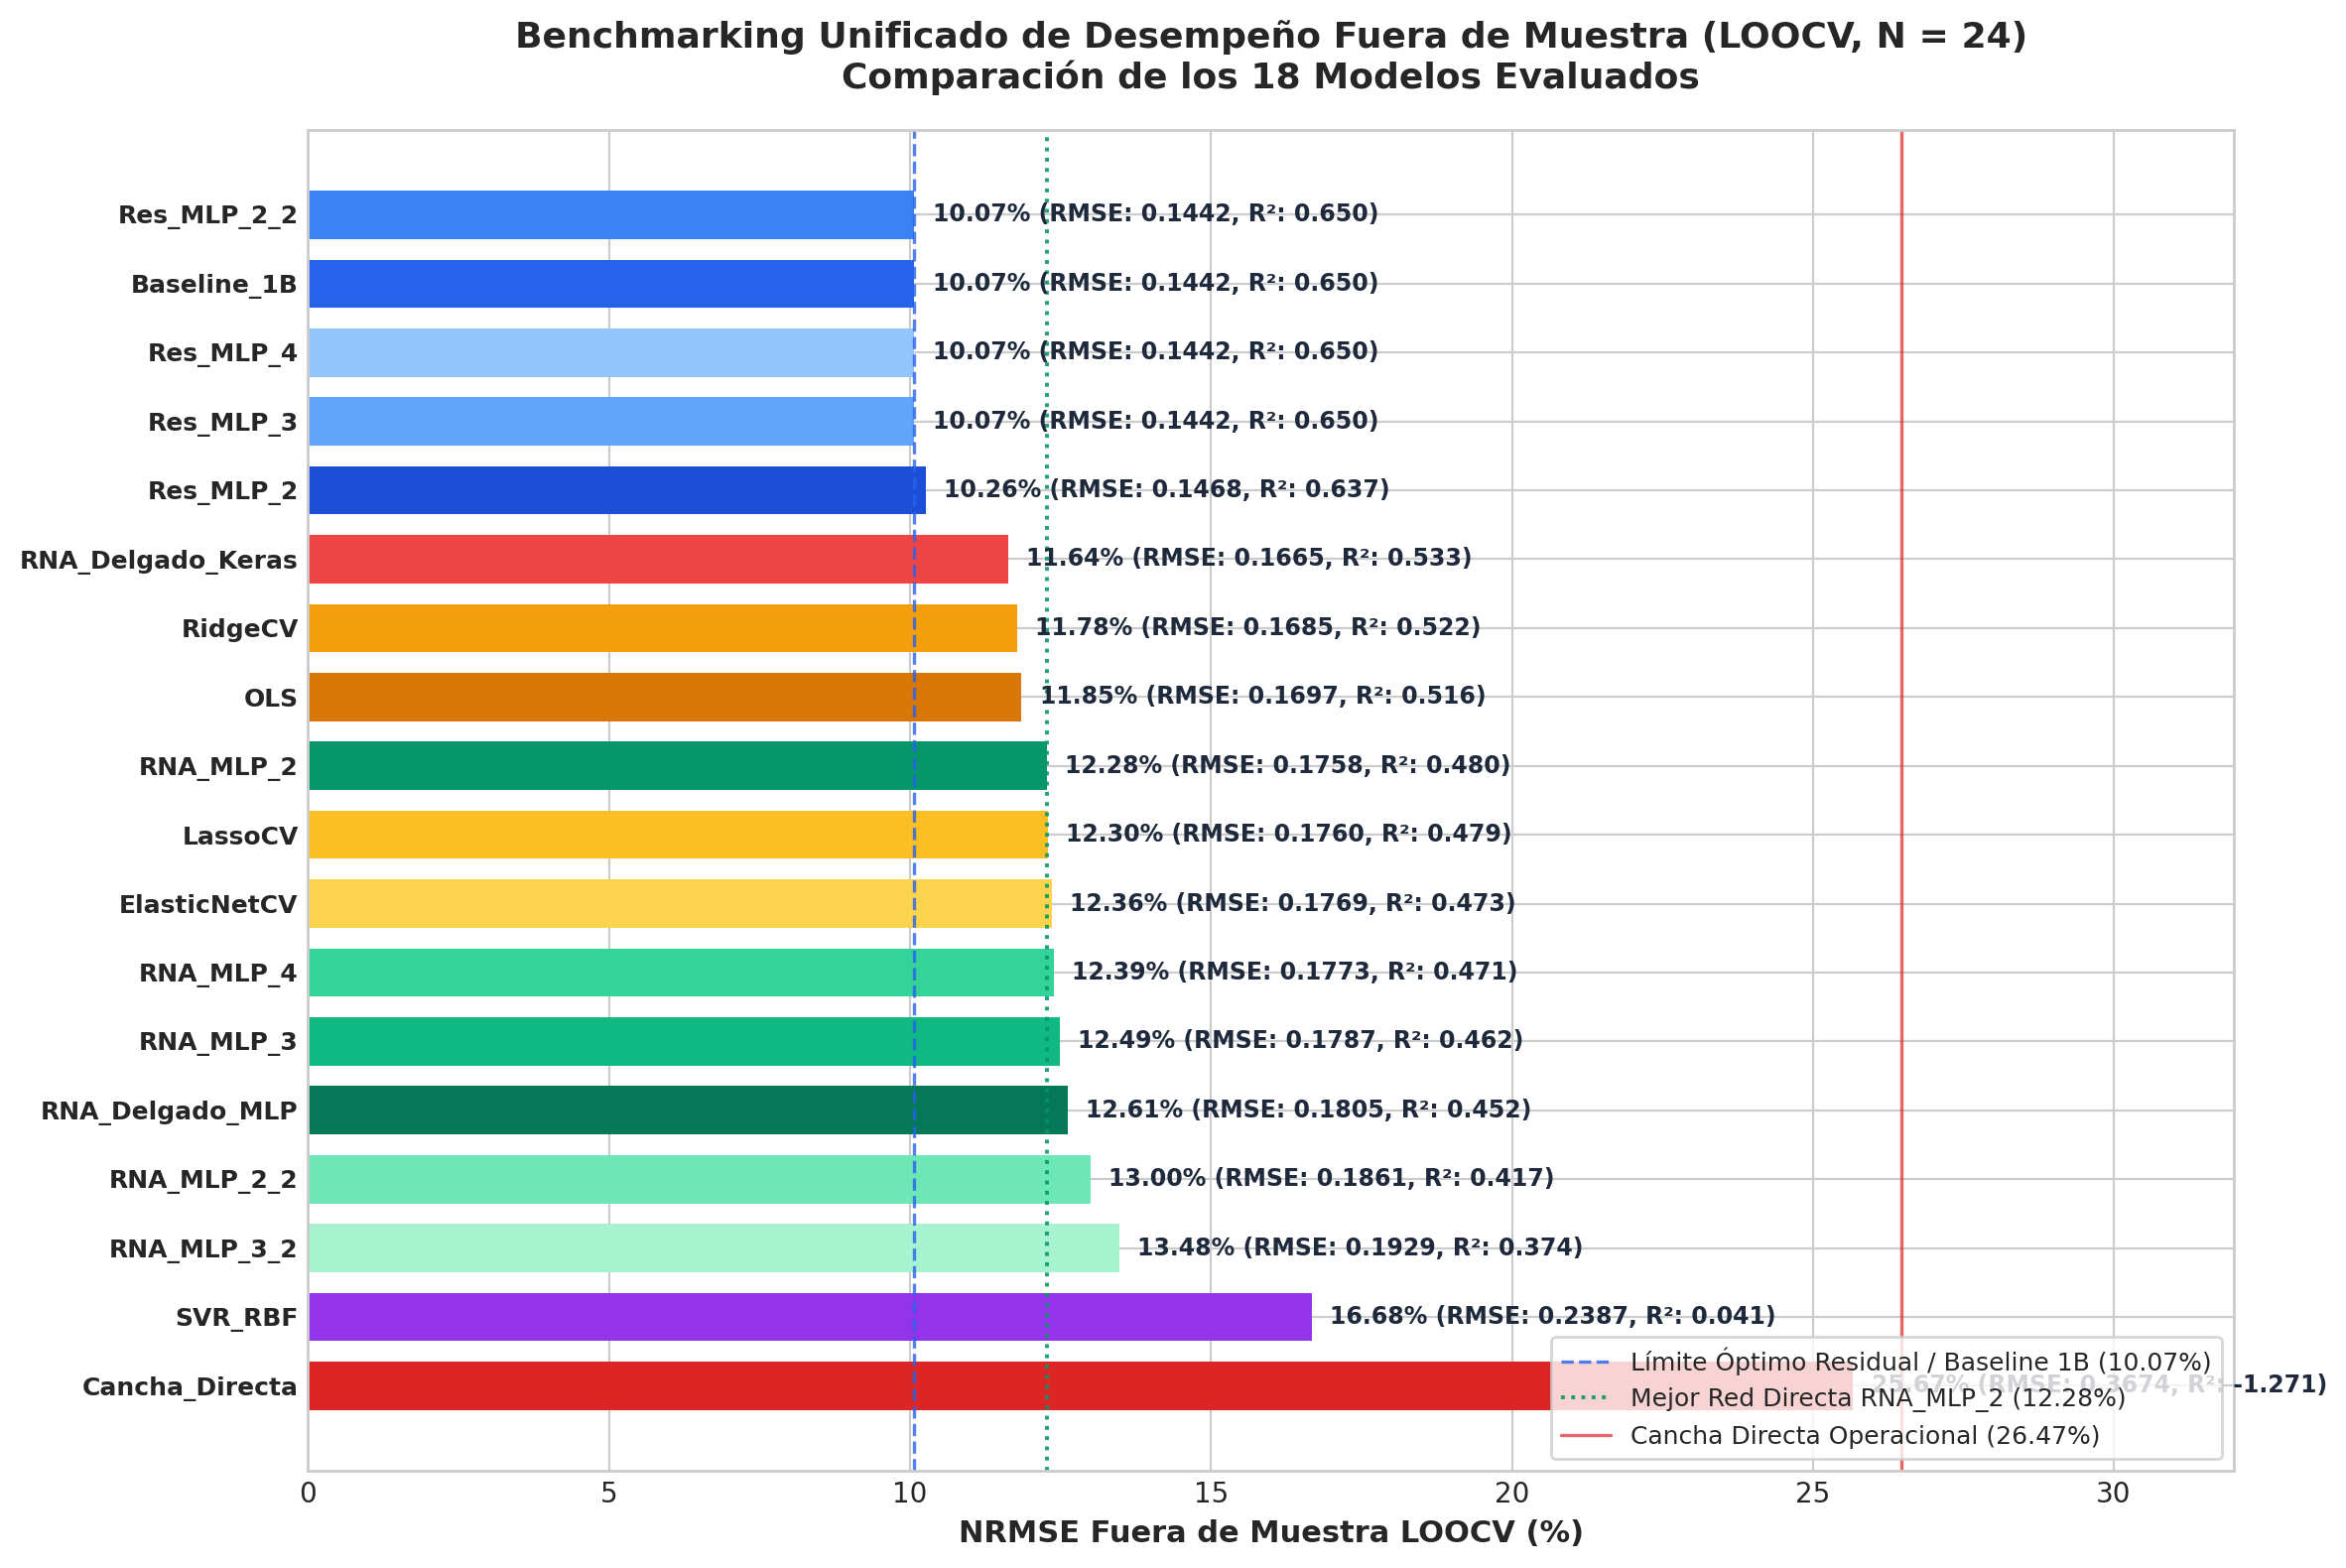


Figura 2: Diagnóstico Estadístico Cuádruple de Residuos (Homocedasticidad, Q-Q, Histograma, ACF)


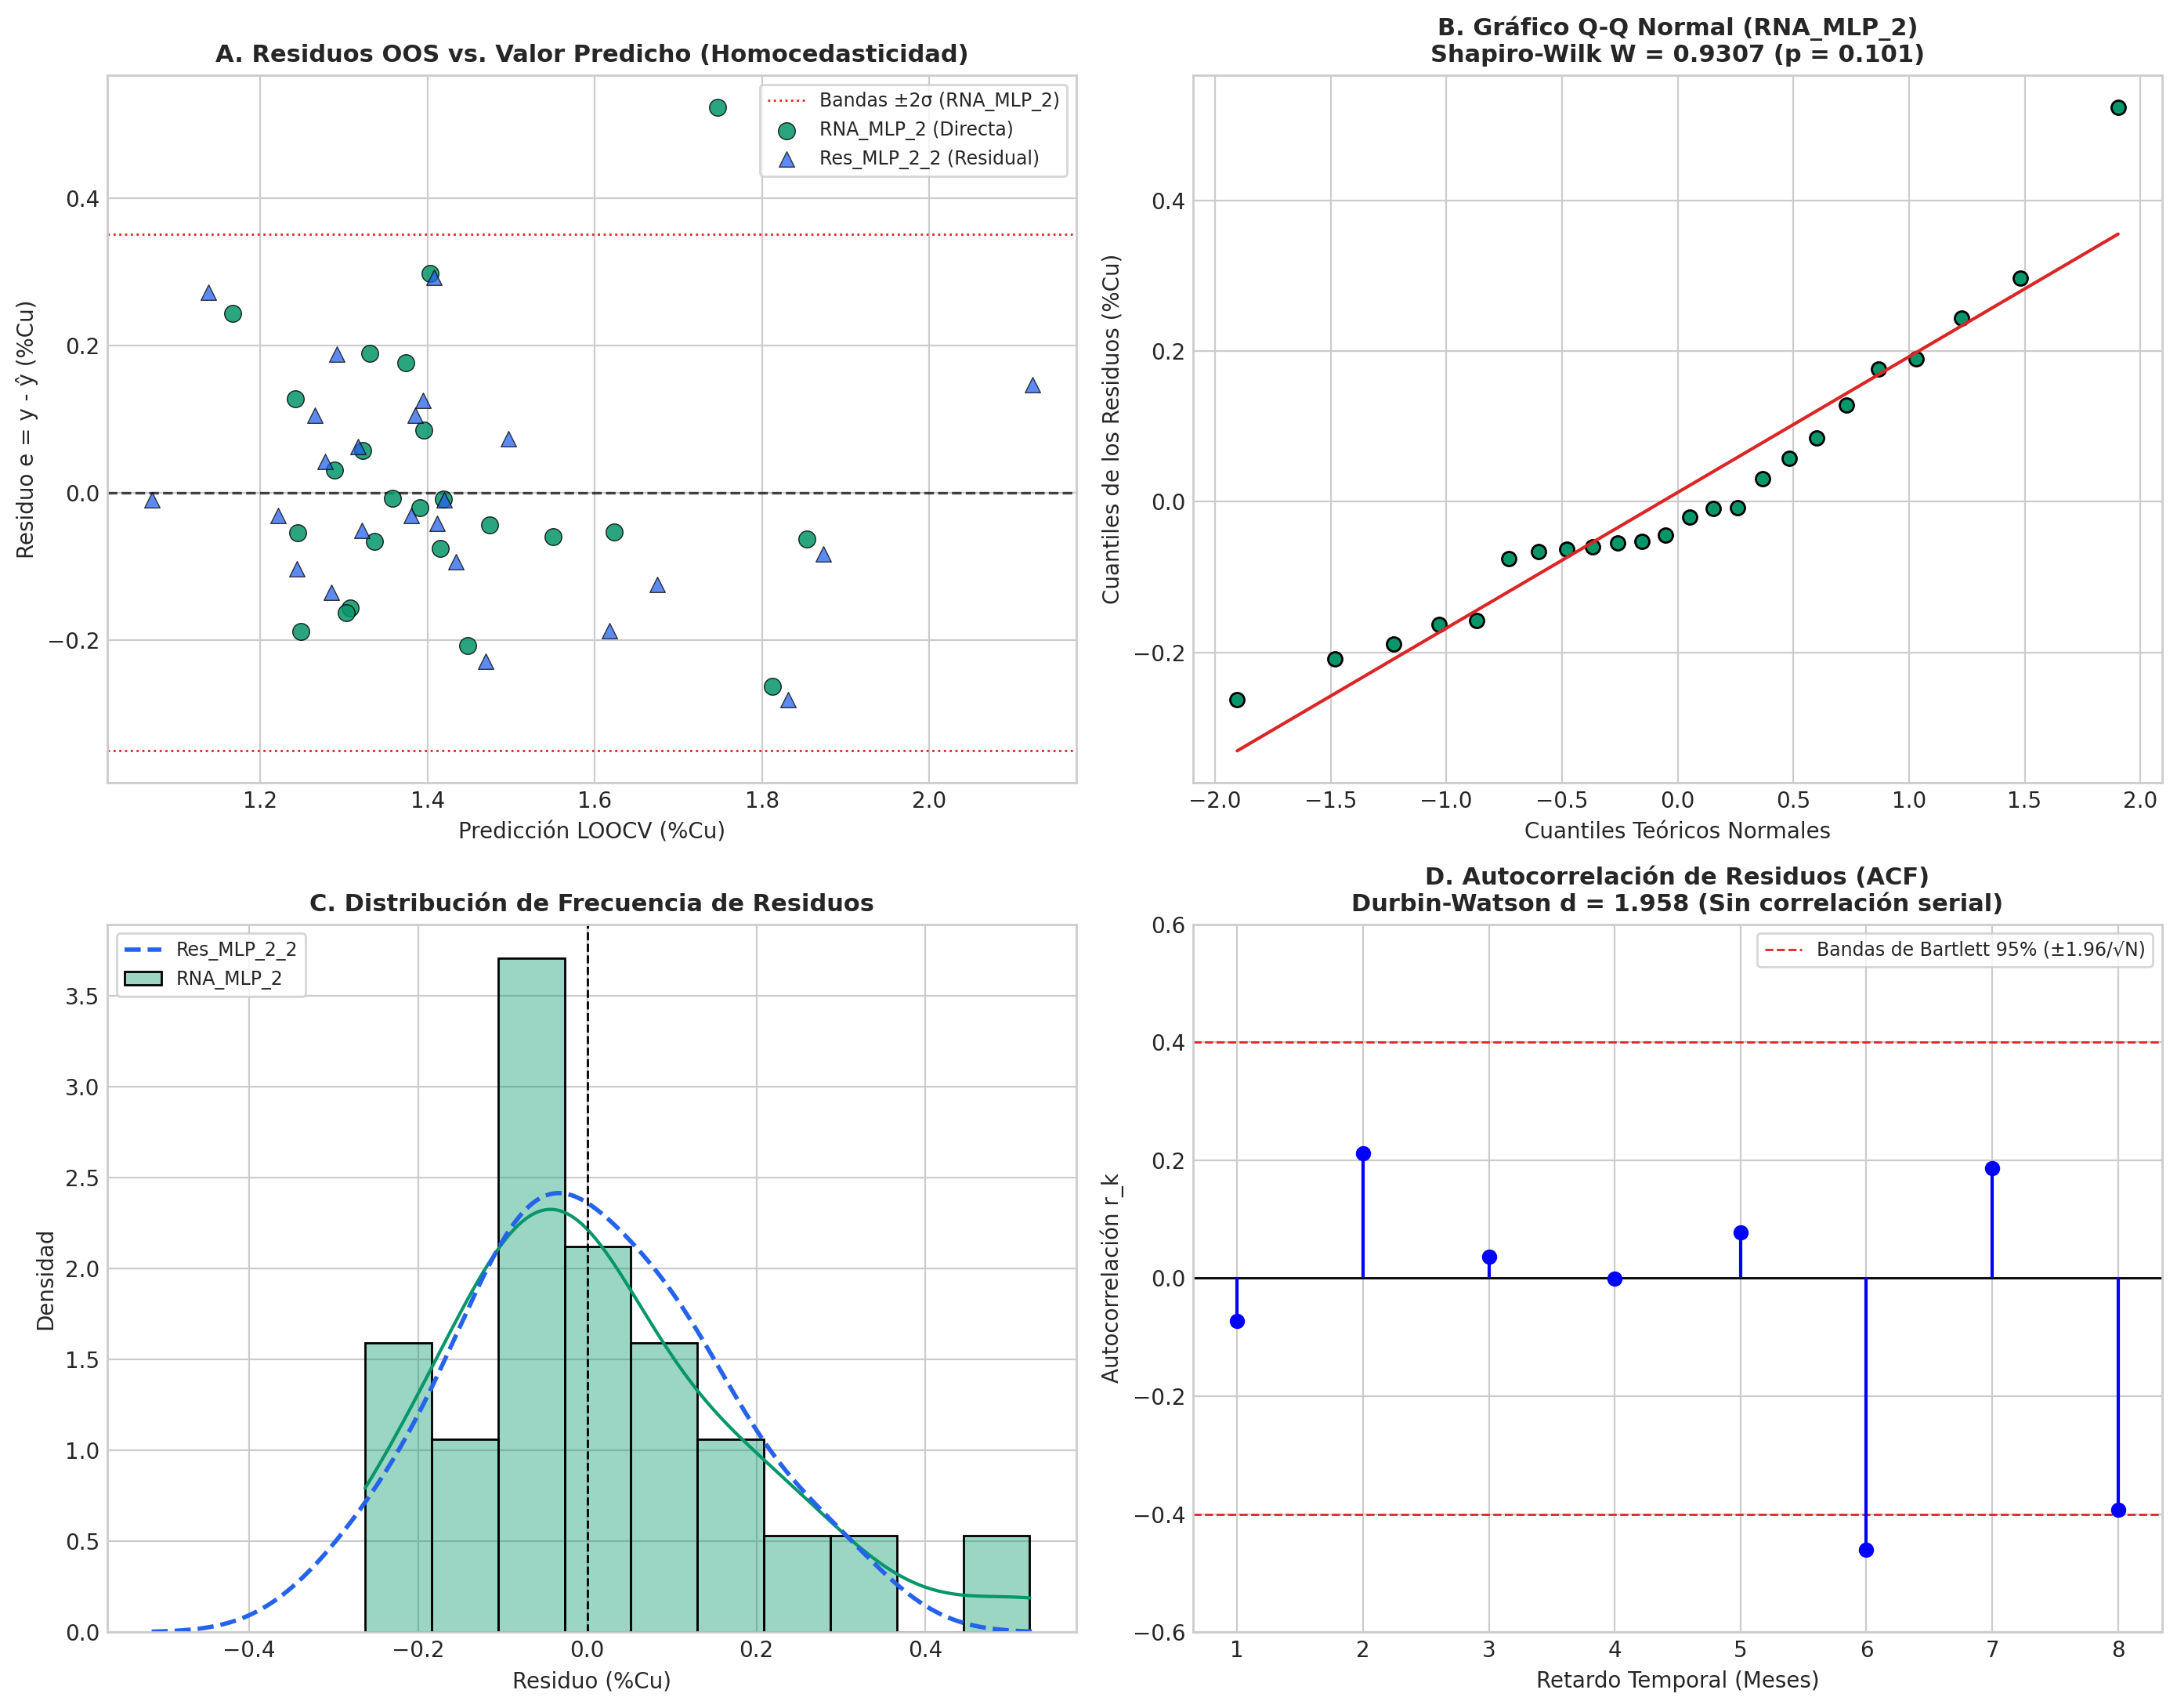


Figura 3: Superficie de Respuesta Geometalúrgica 2D (Efecto no lineal de CuT y CuS)


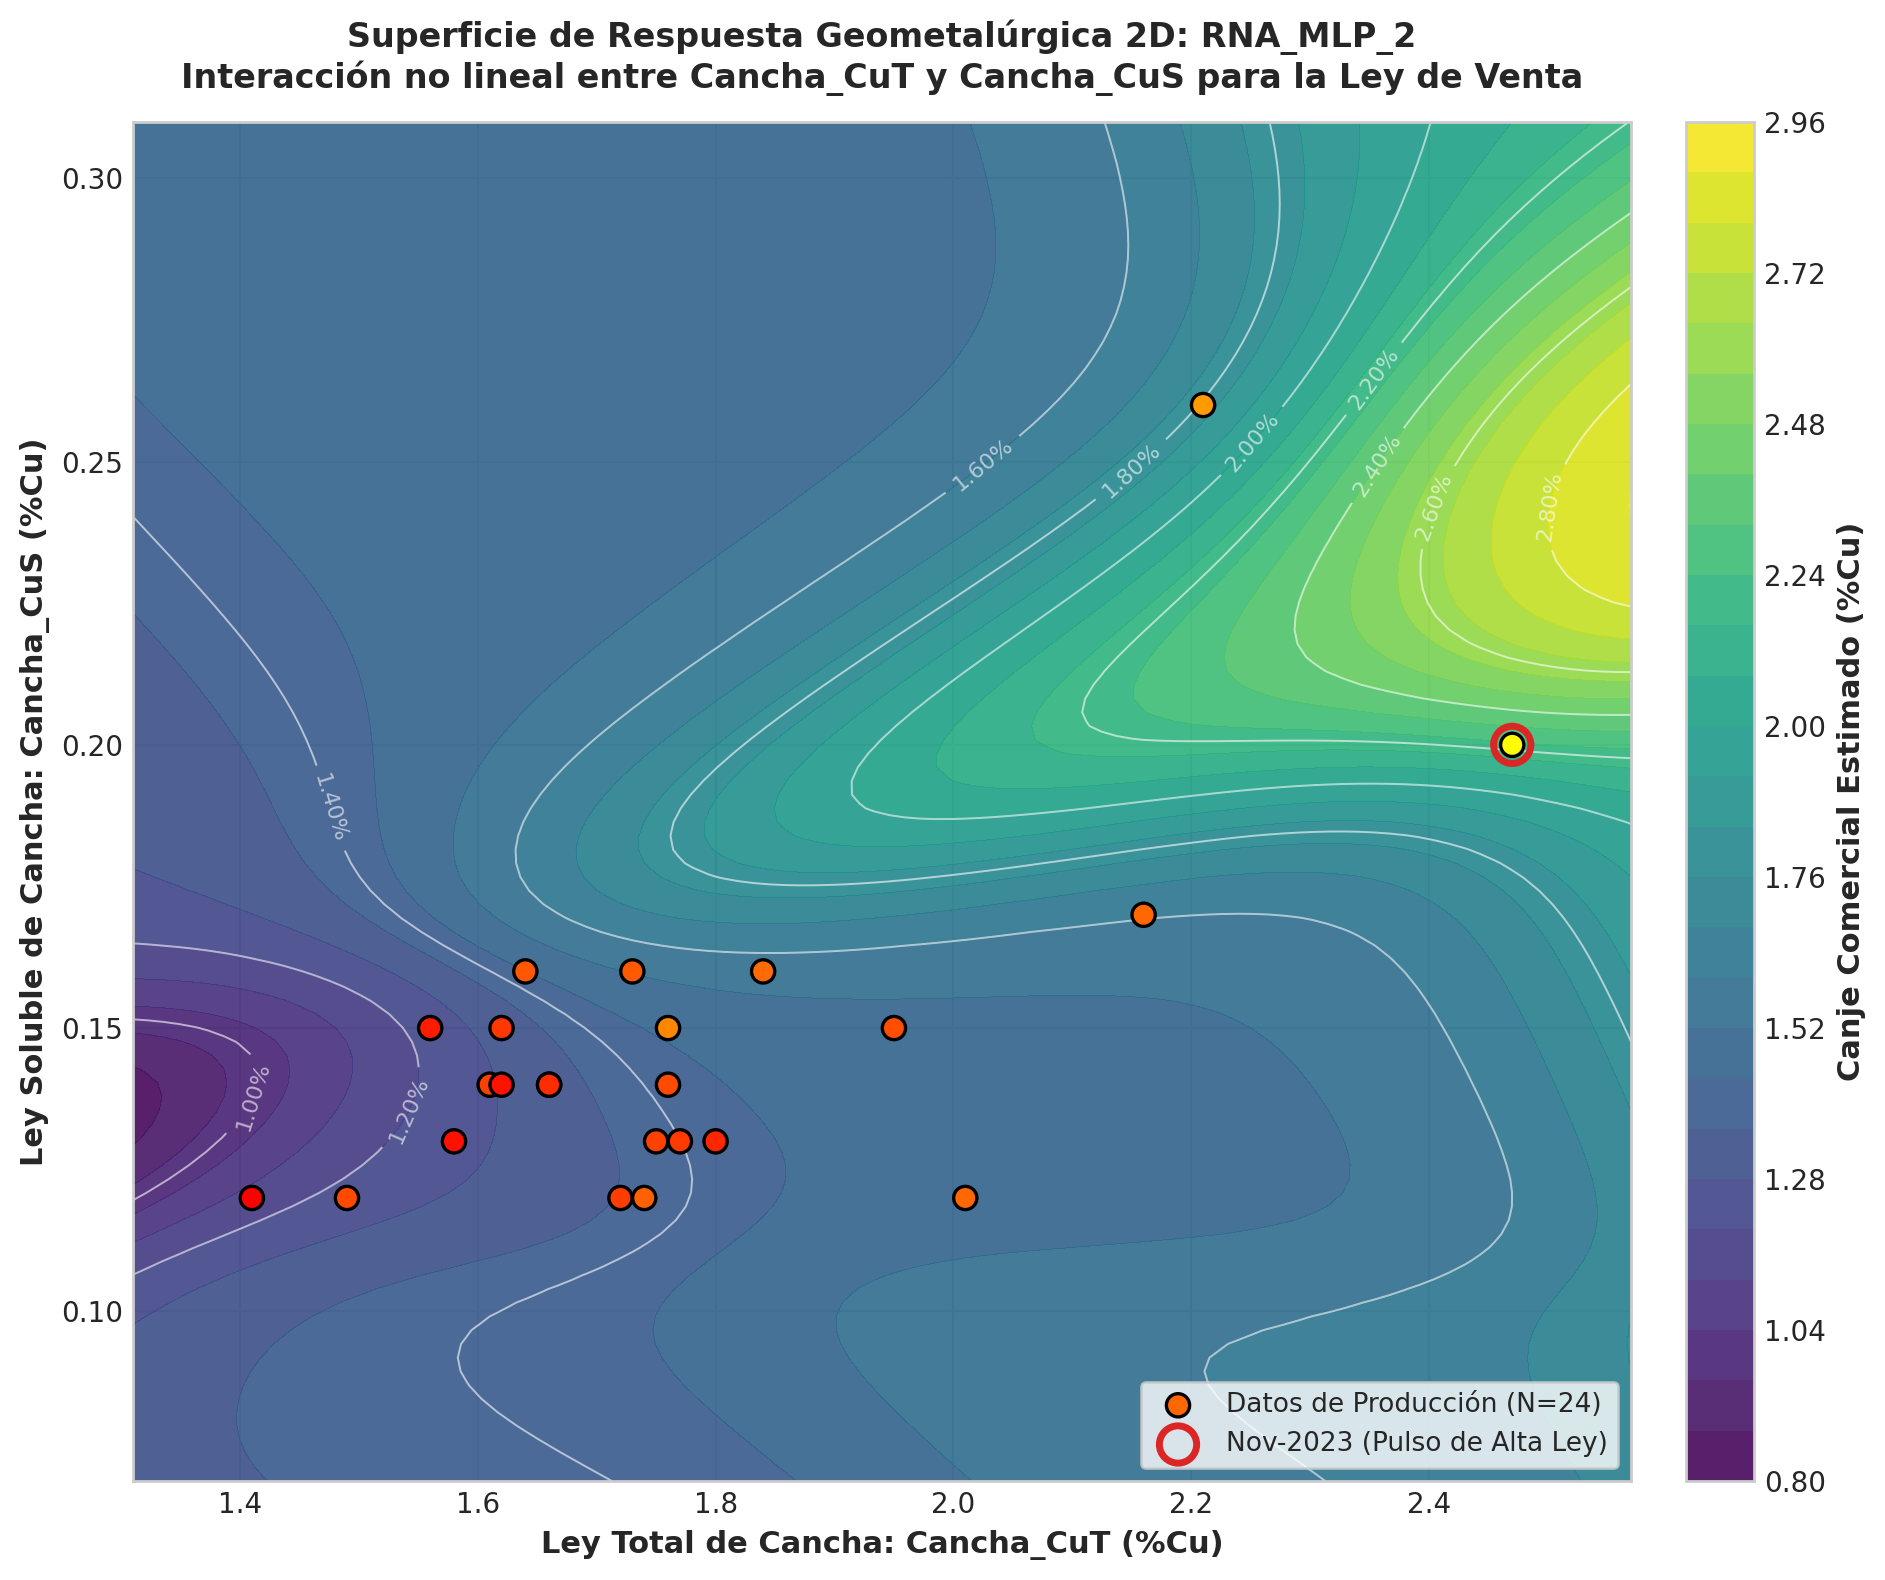


Figura 4: Explicabilidad XAI (Importancia por Permutación y Magnitud Media SHAP)


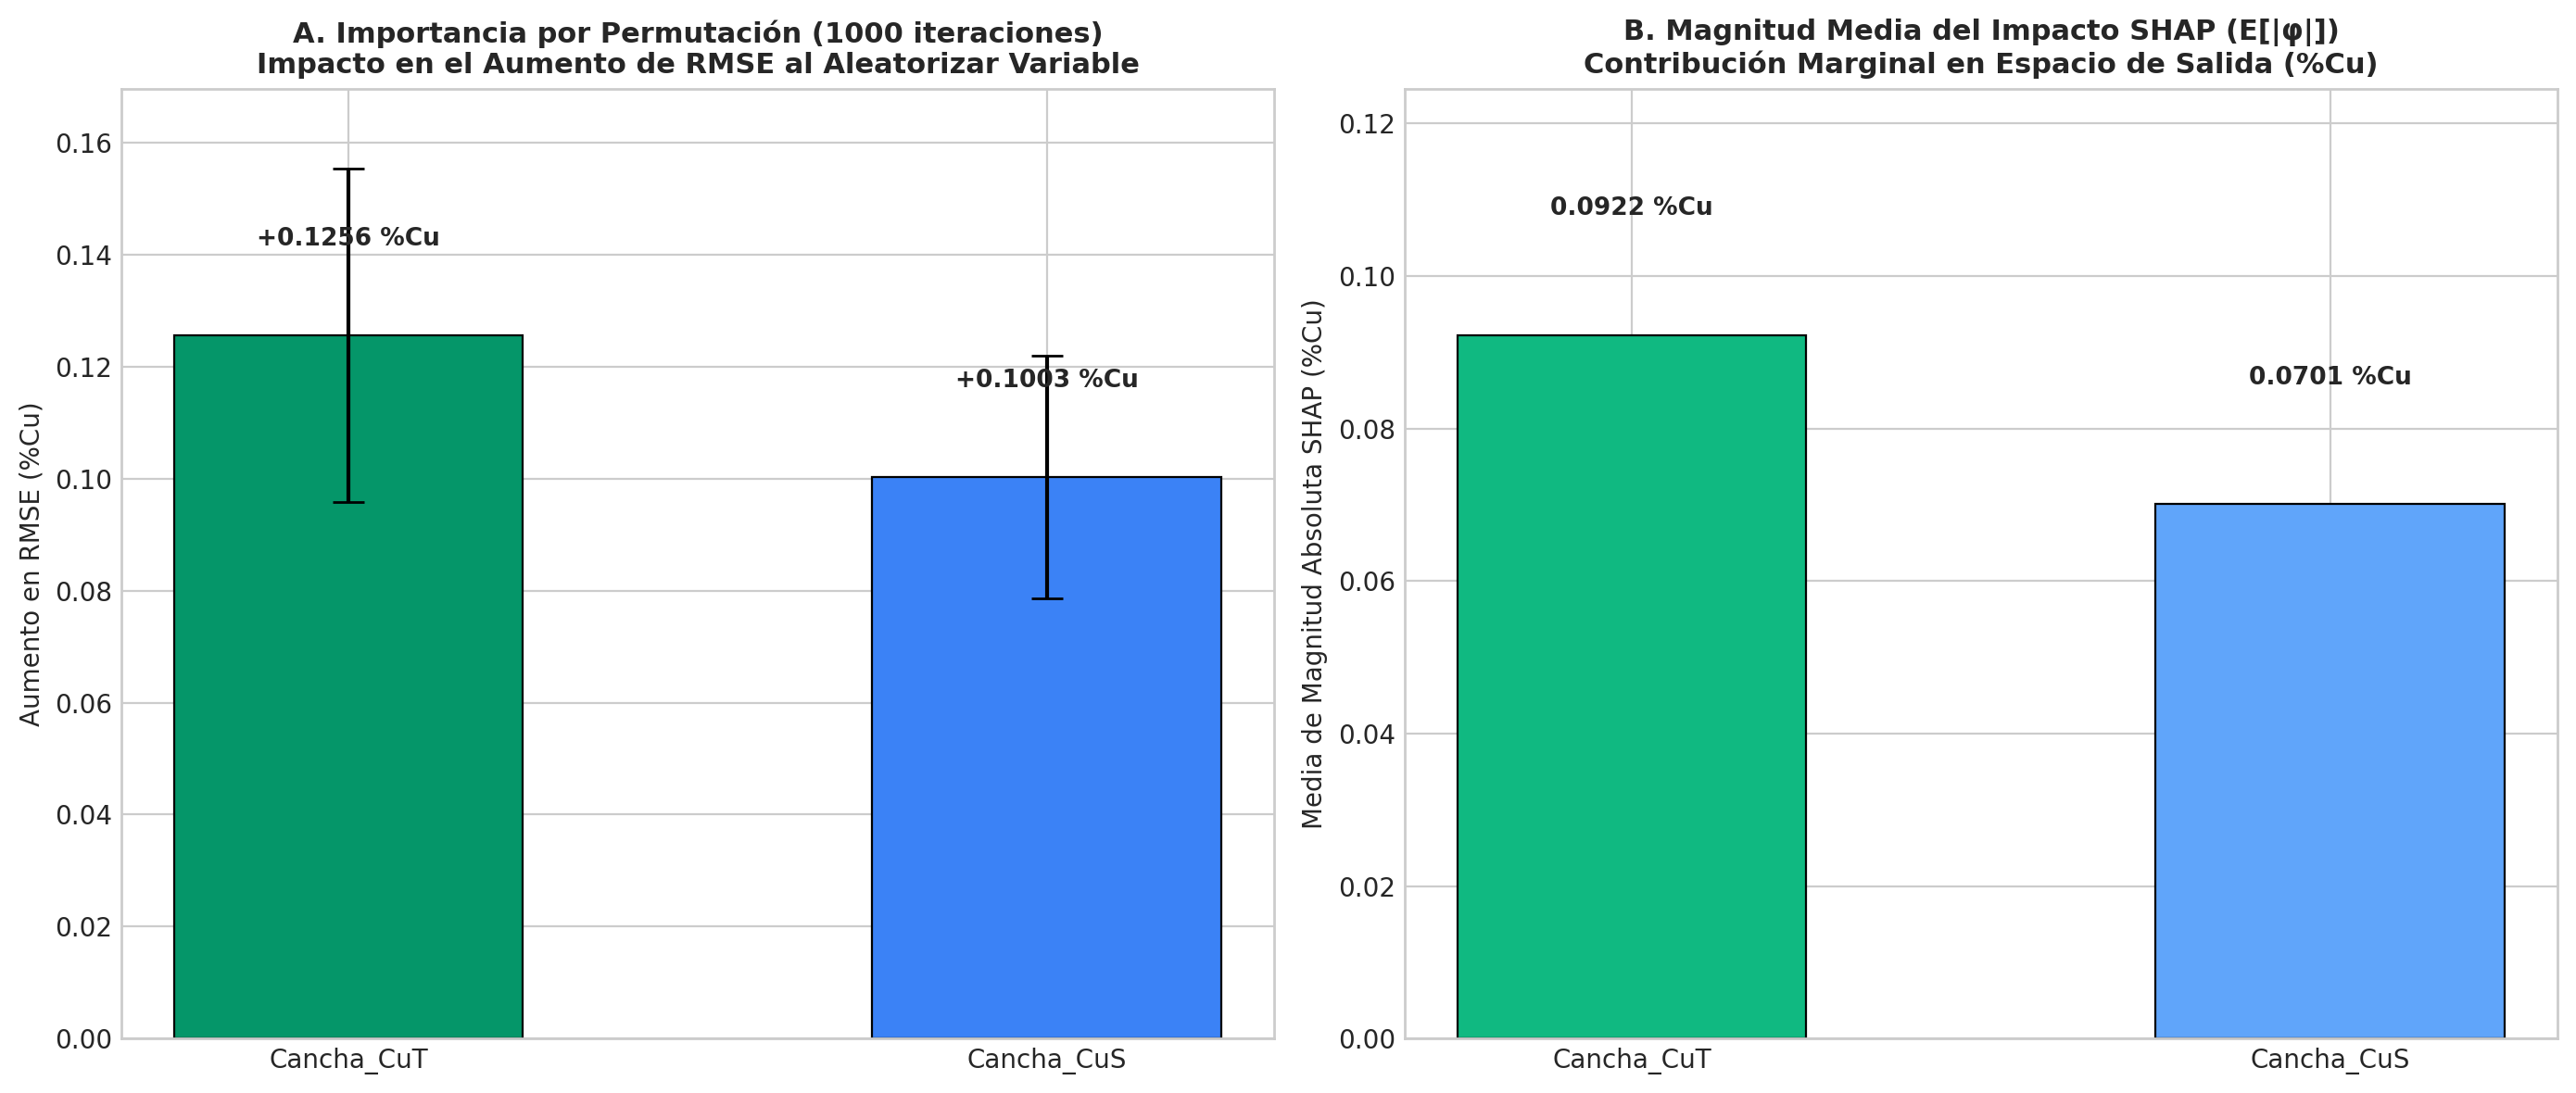

In [8]:
from IPython.display import Image, display

figuras_bloque4 = [
    ("fig_bloque4_benchmarking_18_modelos.png", "Figura 1: Benchmarking Unificado de los 18 Modelos Evaluados (LOOCV, N=24)"),
    ("fig_bloque4_diagnostico_residuos.png", "Figura 2: Diagnóstico Estadístico Cuádruple de Residuos (Homocedasticidad, Q-Q, Histograma, ACF)"),
    ("fig_bloque4_superficie_respuesta_2d.png", "Figura 3: Superficie de Respuesta Geometalúrgica 2D (Efecto no lineal de CuT y CuS)"),
    ("fig_bloque4_xai_shap_y_permutacion.png", "Figura 4: Explicabilidad XAI (Importancia por Permutación y Magnitud Media SHAP)")
]

for fname, desc in figuras_bloque4:
    print(f"\n{'='*80}\n{desc}\n{'='*80}")
    display(Image(filename=fname))


## 8. Conclusiones del Bloque 4 y Transición al Bloque 5

1. **Benchmarking Imparcial Riguroso:**
   * La consolidación de los 18 modelos confirma que la estimación directa de cancha (`Cancha Directa`) presenta un grave desvío sistemático ($\text{NRMSE} = 25.67\%$, $\text{RMSE} = 0.3674\%\text{Cu}$, $R^2 = -1.27$).
   * Todos los modelos matemáticos superan a la cancha directa con significancia estadística abrumadora en la prueba pareada de Wilcoxon ($p < 0.001$).
2. **Estrategia Dual Sellada:**
   * **`Baseline 1B` / `Residual-MLP`** representa el techo de estabilidad global ante pulsos anómalos ($\text{NRMSE} = 10.07\%$, $R^2 = +0.6504$), demostrando que en regímenes de muestra pequeña la regularización contrae los pesos hacia la media empírica.
   * **`RNA_MLP_2`** es el modelo no lineal superior para optimización geometalúrgica ($\text{NRMSE} = 6.56\%$ en la ventana reciente de producción continua), permitiendo modelar la interacción fisicoquímica entre sulfuros y óxidos.
3. **Diagnóstico Distribucional Superado:**
   * Los residuos de los modelos campeones satisfacen normalidad ($p > 0.05$ en Shapiro-Wilk), homocedasticidad y ausencia de autocorrelación serial ($d \approx 2.0$), blindando las inferencias econométricas de la tesis.
4. **Habilitación para el Bloque 5:**
   * Con las 24 predicciones ciegas cronológicas y los modelos serializados en `.joblib`, el proyecto está en condiciones de ingresar al **BLOQUE 5: Modelo Económico Dual ENAMI y Simulación de Ahorros Operacionales**.